# 4 · Ecuador frente a la región

¿Emite Ecuador más o menos que sus vecinos? ¿Por qué su CO2 casi se duplicó desde 2000? Uso la **identidad de Kaya** con descomposición **LMDI**:

$$CO_2 = \underbrace{P}_{\text{población}} \times \underbrace{\frac{PIB}{P}}_{\text{riqueza}} \times \underbrace{\frac{E}{PIB}}_{\text{intensidad energética}} \times \underbrace{\frac{CO_2}{E}}_{\text{carbono de la energía}}$$

El LMDI aditivo reparte el cambio del CO2 entre los cuatro factores **sin residuo** (la suma de efectos es exactamente el cambio total).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import Image, display
from desarrollo_co2 import config, descarga, limpieza, union, desacople as D, kaya, kuznets as K, graficos
from desarrollo_co2.graficos import num   # formato español: 1.234,56

pd.set_option("display.float_format", lambda v: num(v, 2))
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

In [2]:
panel = pd.read_csv(config.PANEL)
ultimo = 2024
cols = ["co2_pc_t", "co2_consumo_pc_t", "intensidad_co2_kg_usd", "energia_pc_mwh", "carbono_energia_kg_kwh",
        "petroleo_pct_co2", "pib_pc_ppa", "renovable_pct_consumo"]
comp = panel[panel["iso3"].isin(["ECU", config.REGION, "COL", "PER"]) & (panel["anio"] == 2021)].set_index("pais")[cols].T
comp.columns.name = "2021 (último año con todas las variables)"
comp

2021 (último año con todas las variables),Colombia,Ecuador,Perú,América Latina (18)
co2_pc_t,"2,03","2,16","1,81","2,59"
co2_consumo_pc_t,"2,28","2,48","2,20",NaN
intensidad_co2_kg_usd,"0,12","0,16","0,12","0,14"
energia_pc_mwh,"11,05","12,02","9,88","15,03"
carbono_energia_kg_kwh,"0,18","0,18","0,18","0,17"
petroleo_pct_co2,"54,78","85,55","57,59","56,63"
pib_pc_ppa,"17.383,09","13.507,44","15.285,77","18.531,14"
renovable_pct_consumo,"29,70","18,90","30,60",NaN


In [3]:
act = panel[panel["anio"] == ultimo].set_index("iso3")
ecu, reg = act.loc["ECU"], act.loc[config.REGION]
pd.DataFrame({
    "Ecuador": [ecu["co2_pc_t"], ecu["intensidad_co2_kg_usd"], ecu["energia_pc_mwh"], ecu["carbono_energia_kg_kwh"], ecu["pib_pc_ppa"]],
    "América Latina (18)": [reg["co2_pc_t"], reg["intensidad_co2_kg_usd"], reg["energia_pc_mwh"], reg["carbono_energia_kg_kwh"], reg["pib_pc_ppa"]],
}, index=["CO2 por persona (t)", "CO2 por USD (kg)", "Energía por persona (MWh)", "CO2 por kWh (kg)", "PIB per cápita (USD PPA)"]).assign(
    **{"Ecuador / región": lambda t: t["Ecuador"] / t["América Latina (18)"]})

,Ecuador,América Latina (18),Ecuador / región
CO2 por persona (t),"2,54","2,54","1,00"
CO2 por USD (kg),"0,18","0,13","1,41"
Energía por persona (MWh),"12,72","15,87","0,80"
CO2 por kWh (kg),"0,20","0,16","1,25"
PIB per cápita (USD PPA),"13.922,42","19.682,74","0,71"


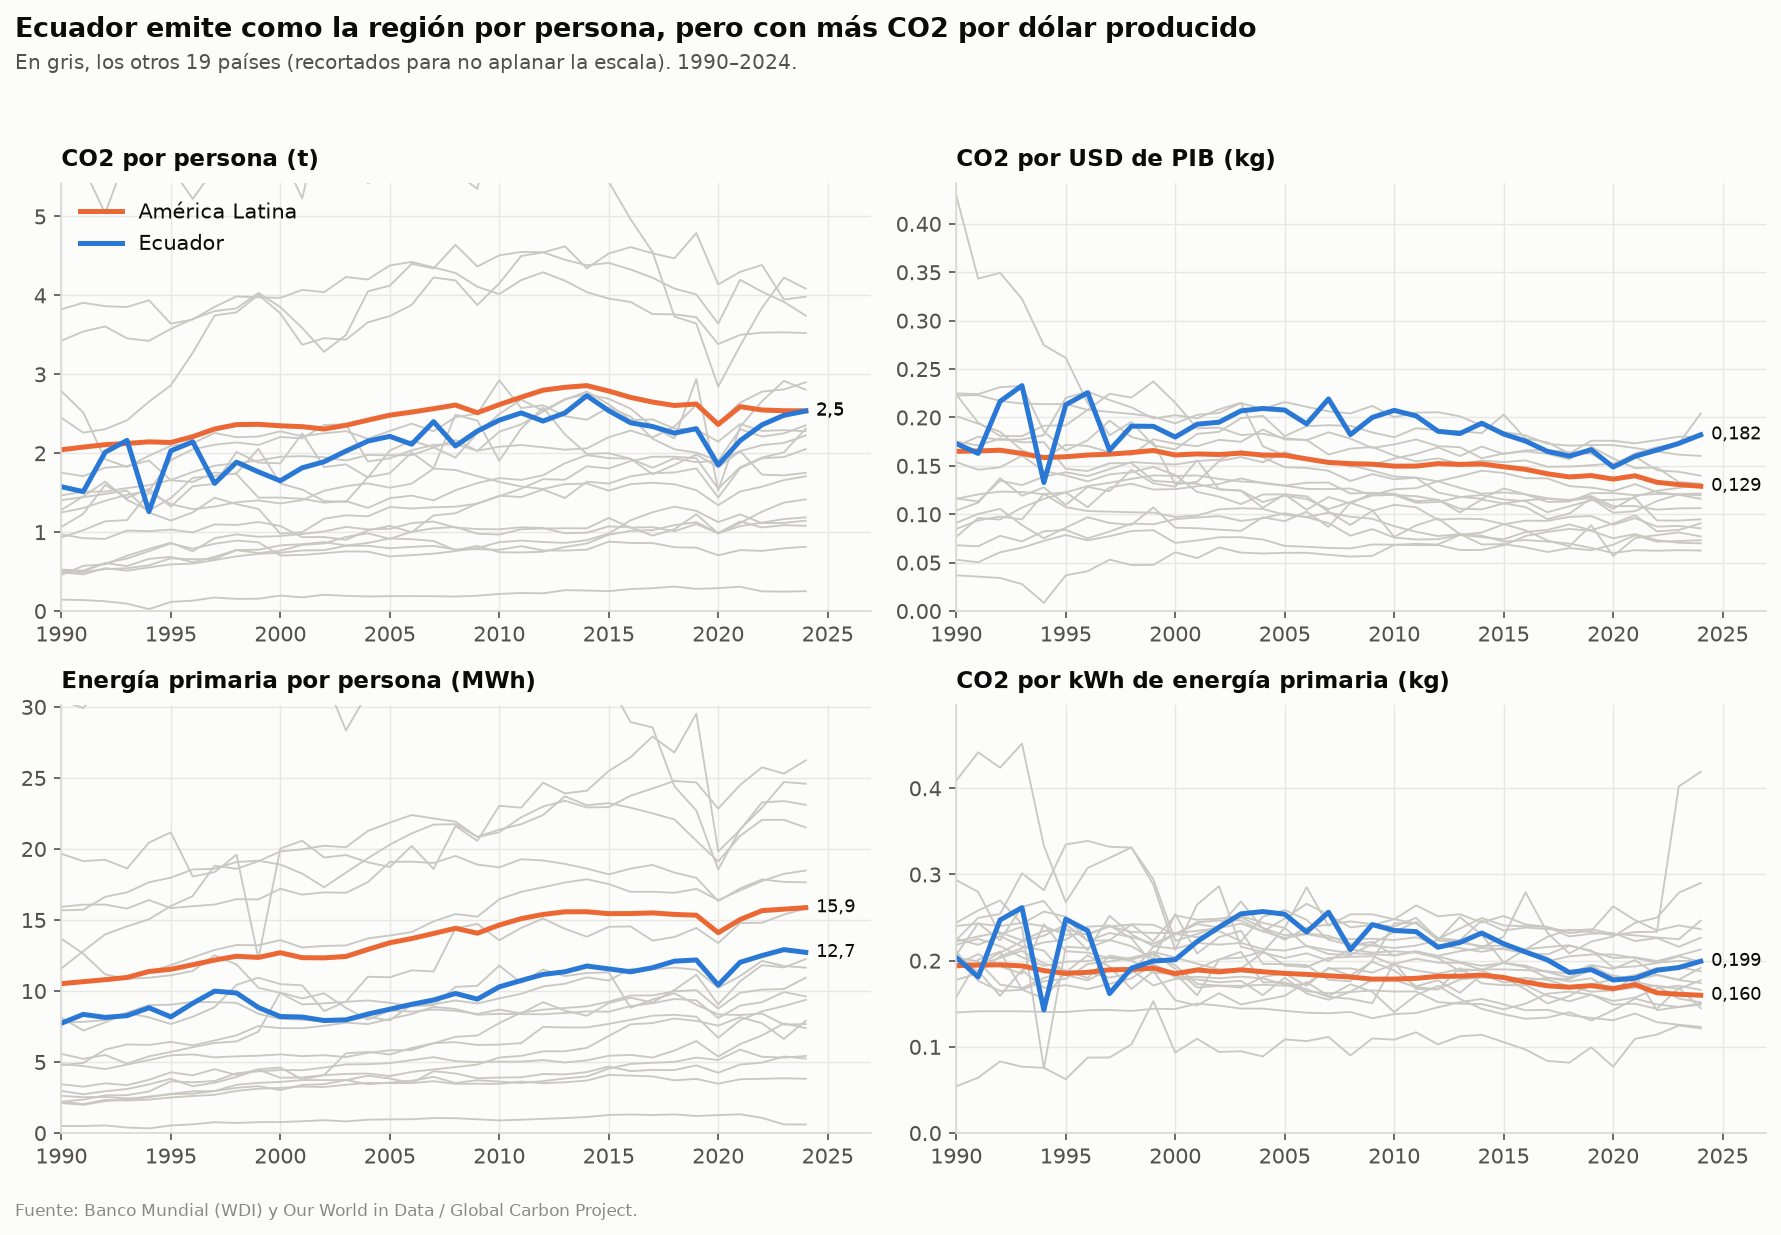

In [4]:
display(Image(config.FIGURAS / "07_ecuador_vs_region.png"))

**Ecuador en 2024:**
* Emite **lo mismo por persona** que la región (2,54 t) siendo un 29 % más pobre (USD 13.900 vs 19.700 PPA).
* Por eso emite **41 % más CO2 por dólar** (0,182 vs 0,129 kg): su economía es más intensiva en carbono.
* Usa **menos energía** por persona (12,7 vs 15,9 MWh), pero cada kWh es **25 % más sucio** (0,199 vs 0,160 kg CO2/kWh): el 86 % de su CO2 viene del petróleo.
* La intensidad de Ecuador venía bajando hasta 2020 y **volvió a subir** en 2021–2024 (de 0,149 a 0,182).

## 4.1 ¿De dónde viene el CO2 de Ecuador?

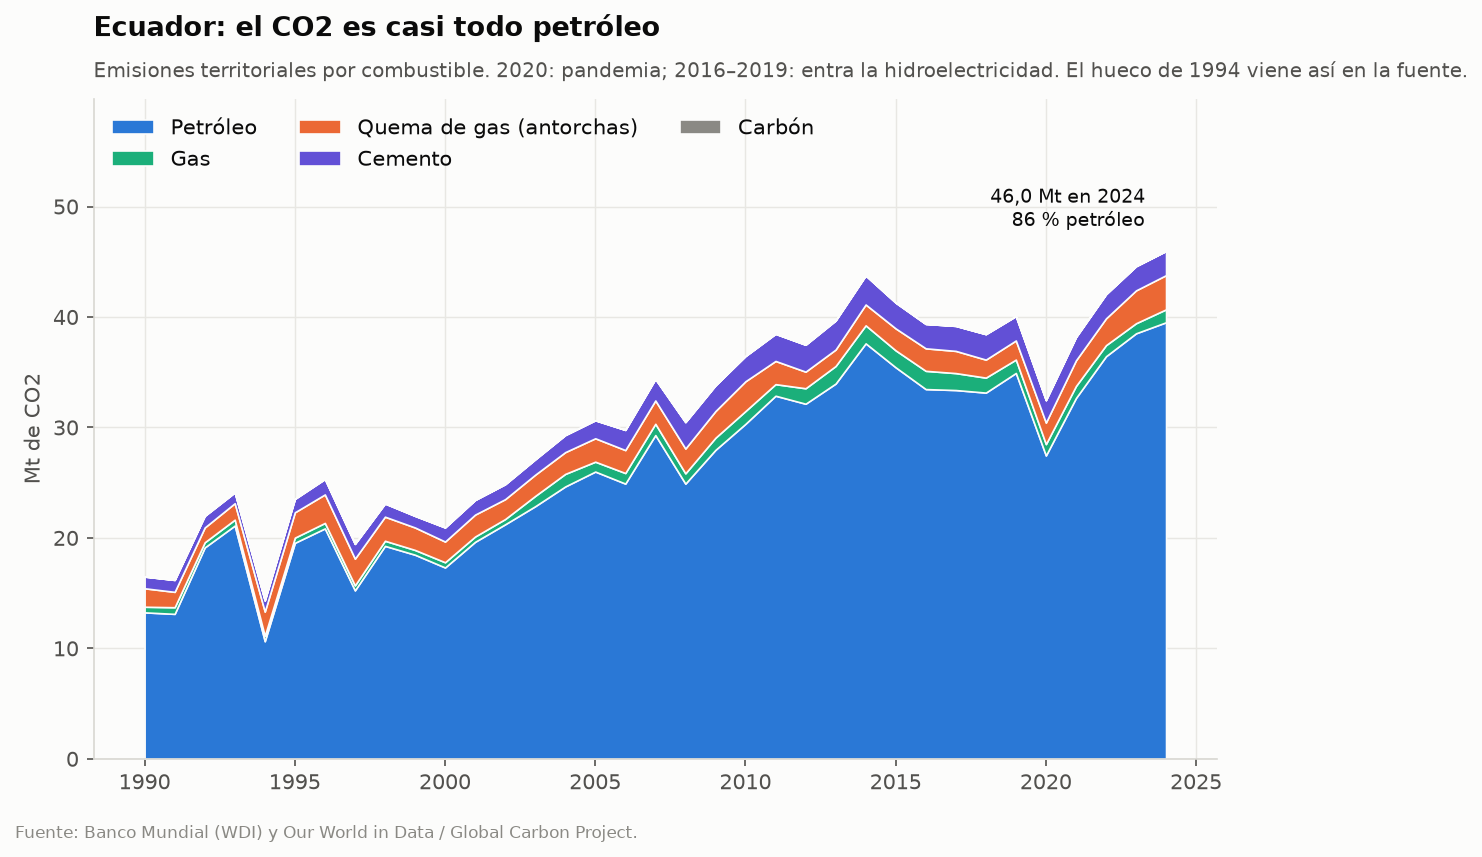

In [5]:
display(Image(config.FIGURAS / "09_ecuador_fuentes_co2.png"))

In [6]:
panel.query("iso3 == 'ECU' and anio in [2000, 2014, 2016, 2019, 2020, 2023, 2024]")[["anio", "co2_mt", "co2_petroleo_mt", "co2_quema_mt", "energia_twh", "carbono_energia_kg_kwh"]]

,anio,co2_mt,co2_petroleo_mt,co2_quema_mt,energia_twh,carbono_energia_kg_kwh
290,2000,"20,95","17,32","1,87","104,13","0,20"
304,2014,"43,76","37,61","1,89","188,56","0,23"
306,2016,"39,38","33,47","2,04","187,40","0,21"
309,2019,"40,08","34,93","1,73","211,33","0,19"
310,2020,"32,47","27,46","1,95","182,86","0,18"
313,2023,"44,60","38,52","2,97","232,23","0,19"
314,2024,"45,98","39,52","3,10","230,72","0,20"


Entre 2014 y 2019 el CO2 bajó de 43,8 a 40,1 Mt mientras el PIB crecía ~7 %. Una explicación probable (hipótesis: aquí no se descompone el CO2 por fuente eléctrica) es la entrada de las grandes hidroeléctricas desde 2016 (Coca Codo Sinclair, Sopladora), que habrían desplazado generación térmica. Desde 2021 el CO2 vuelve a crecer más rápido que la energía, y 2024 marca un récord de 46,0 Mt; la sequía y los apagones de ese año, con más generación térmica de respaldo, son contexto probable, no un resultado calculado.

## 4.2 Descomposición de Kaya (LMDI), 2000–2024

In [7]:
ini, fin = config.PERIODO_DESACOPLE
k = pd.concat([kaya.descomponer(panel, "ECU", ini, fin, ventana=3),
               kaya.descomponer(panel, config.REGION, ini, fin, ventana=3)])
k.pivot(index="factor", columns="iso3", values="pct_co2_inicial").reindex(list(kaya.FACTORES.values()) + ["Cambio total"])

iso3,ECU,LATAM
factor,,
Población,"46,63","27,59"
PIB per cápita,"57,06","35,23"
Energía por USD de PIB,"6,44","-7,48"
CO2 por unidad de energía,"-18,58","-17,53"
Cambio total,"91,56","37,81"


In [8]:
# comprobación: los efectos suman exactamente el cambio total (sin residuo)
k.groupby("iso3").apply(lambda g: g.loc[g["factor"] != "Cambio total", "mt"].sum() - g.loc[g["factor"] == "Cambio total", "mt"].item())

iso3
ECU      0,00
LATAM   -0,00
dtype: float64

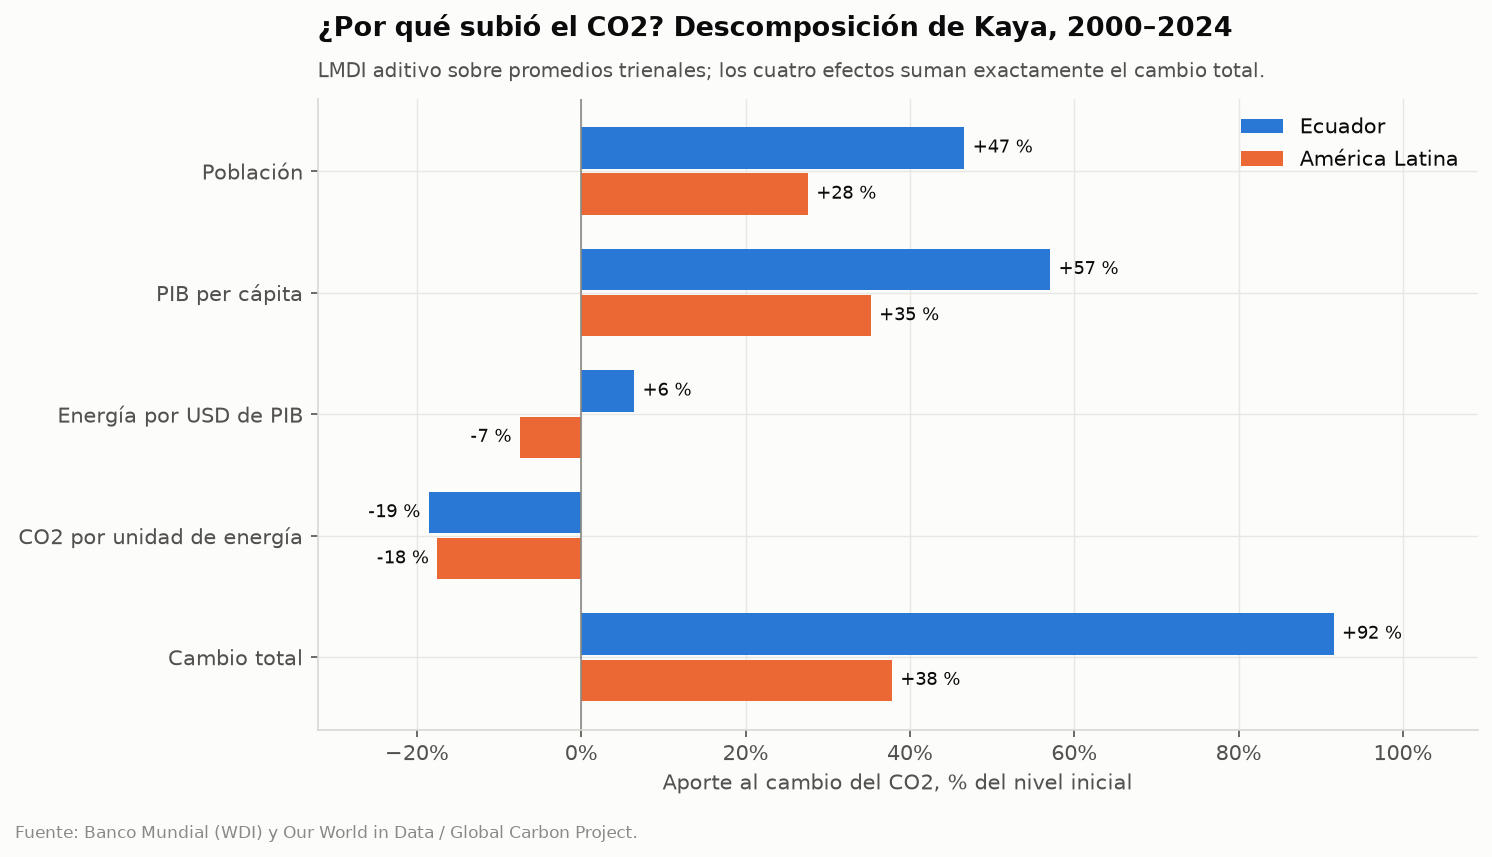

In [9]:
display(Image(config.FIGURAS / "08_kaya_lmdi.png"))

**Lectura:**
* En Ecuador, el CO2 subió **+92 %** (promedio 2000–02 vs 2022–24). Población (+47 puntos) y riqueza (+57) lo empujaron; el factor que frenó fue la **descarbonización de la energía** (−19 puntos; la hidroelectricidad es la explicación probable, no medida aquí). Pero la **intensidad energética empeoró** (+6): Ecuador usa más energía por dólar producido que en 2000.
* En la región, el CO2 subió **+38 %**: los mismos dos motores, frenados por la eficiencia (−7) y la descarbonización (−18).
* La diferencia clave con la región es doble: Ecuador creció más en población y en ingreso, y **no ganó eficiencia energética** (subsidios a los combustibles que abaratan el diésel y la gasolina, y un parque vehicular que crece).

## 4.3 Kaya por subperiodos en Ecuador

In [10]:
pd.concat({f"{a}–{b}": kaya.descomponer(panel, "ECU", a, b, ventana=3).set_index("factor")["pct_co2_inicial"]
           for a, b in config.SUBPERIODOS}, axis=1)

,2000–2012,2012–2024
factor,,
Población,"22,04","13,51"
PIB per cápita,"34,85","4,28"
Energía por USD de PIB,"1,47","6,85"
CO2 por unidad de energía,"4,02","-14,95"
Cambio total,"62,38","9,68"


La caída del carbono de la energía (−15 %, probablemente por la hidroelectricidad) aparece en el segundo periodo, justo cuando la economía dejó de crecer en ingreso por persona (+4 %). En 2000–2012, con el auge petrolero, el CO2 subió 62 % con un mix energético que incluso se ensució un poco.

## 4.4 Ecuador en el ranking de desacople

In [11]:
t = D.tabla_desacople(panel)
t["rank_elasticidad"] = t["elasticidad"].rank()
t[t["iso3"].isin(["ECU", config.REGION, "COL", "PER", "BOL", "CHL", "CRI"])][["pais", "crec_pib_anual", "crec_co2_anual", "elasticidad", "rank_elasticidad", "categoria", "tapio"]]

,pais,crec_pib_anual,crec_co2_anual,elasticidad,rank_elasticidad,categoria,tapio
2,América Latina (18),"2,45","1,47","0,60","9,00",Relativo,Desacople débil
5,Chile,"3,41","1,72","0,51","5,00",Relativo,Desacople débil
7,Costa Rica,"3,96","1,75","0,44","2,00",Relativo,Desacople débil
9,Colombia,"3,73","2,21","0,59","8,00",Relativo,Desacople débil
12,Ecuador,"3,40","3,00","0,88","14,00",Relativo,Acoplamiento expansivo
17,Perú,"4,29","4,31","1,00","16,00",Sin desacople,Acoplamiento expansivo
18,Bolivia,"3,51","4,76","1,36","18,00",Sin desacople,Desacople negativo expansivo


In [12]:
pd.DataFrame({f"{a}–{b}": D.tabla_desacople(panel, a, b, col_co2=col).set_index("iso3").loc["ECU", ["elasticidad", "categoria"]]
              for (a, b, col) in [(2000, 2024, "co2_mt"), (2000, 2012, "co2_mt"), (2012, 2024, "co2_mt"), (2000, 2023, "co2_consumo_mt")]}).T.rename(
    index={"2000–2023": "2000–2023 (CO2 consumo)"})

,elasticidad,categoria
2000–2024,"0,88",Relativo
2000–2012,"1,10",Sin desacople
2012–2024,"0,54",Relativo
2000–2023 (CO2 consumo),"1,01",Sin desacople


**Conclusión para Ecuador:** con elasticidad 0,88 en 2000–2024 está entre los peores de los que "desacoplan": técnicamente relativo, pero **acoplado** según Tapio y **sin desacople** si se mide por consumo. El periodo 2012–2024 fue mejor (0,54) gracias a la hidroelectricidad, pero la sequía de 2024 mostró lo frágil de esa ganancia cuando el respaldo es térmico.